In [27]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: C:\Users\rohit\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
df = pd.read_csv("diabetes.csv")
print("Dataset shape:", df.shape)

Dataset shape: (768, 9)


In [31]:
print("\nColumn names:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())


Column names: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [32]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [33]:
print(df["Outcome"].value_counts())

Outcome
0    500
1    268
Name: count, dtype: int64


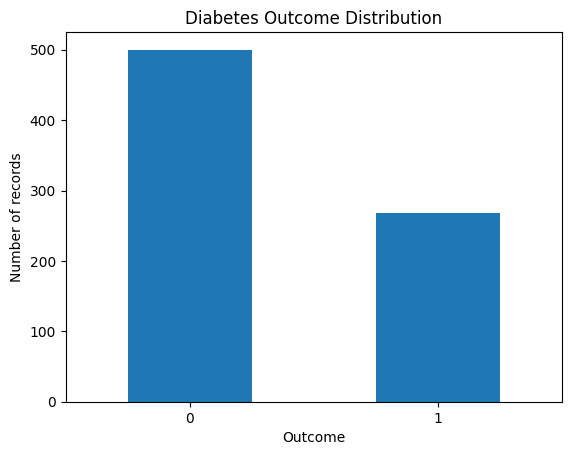

In [34]:
df["Outcome"].value_counts().sort_index().plot(kind="bar", rot=0)
plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("Number of records")
plt.show()

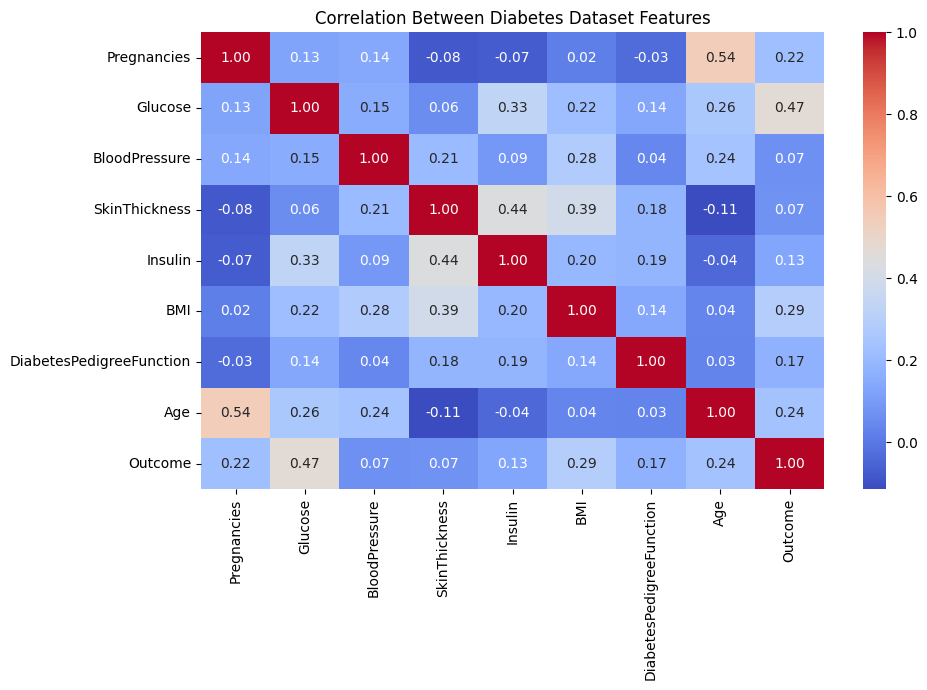

In [35]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Diabetes Dataset Features")
plt.tight_layout()
plt.show()

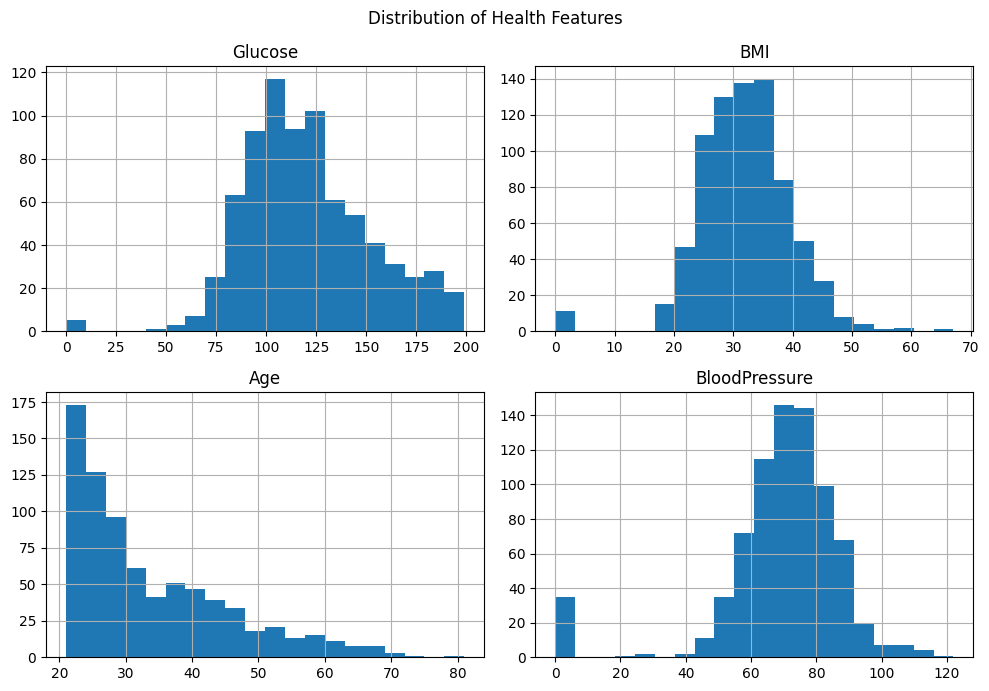

In [36]:
features = ["Glucose", "BMI", "Age", "BloodPressure"]

df[features].hist(figsize=(10, 7), bins=20)
plt.suptitle("Distribution of Health Features")
plt.tight_layout()
plt.show()

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [38]:
data = df.copy()

X = data.drop(columns=["Outcome"])
y = data["Outcome"].astype(int)

In [39]:
if not set(y.unique()).issubset({0, 1}):
    raise ValueError("Outcome must contain only 0 and 1.")

In [40]:
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

X[zero_columns] = X[zero_columns].replace(0, np.nan)

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [42]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ])
}

In [43]:
results = []
trained_models = {}

In [44]:
for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

    results.append(metrics)
    trained_models[name] = model

In [45]:
results_df = pd.DataFrame(results).sort_values(
    "ROC-AUC", ascending=False
)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.708,0.600,0.500,0.545,0.813
1,Random Forest,0.740,0.652,0.556,0.600,0.812


In [46]:
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

predictions = best_model.predict(X_test)

In [47]:
print("Selected model:", best_name)
print("\nClassification report:")
print(classification_report(
    y_test, predictions, zero_division=0
))

Selected model: Logistic Regression

Classification report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



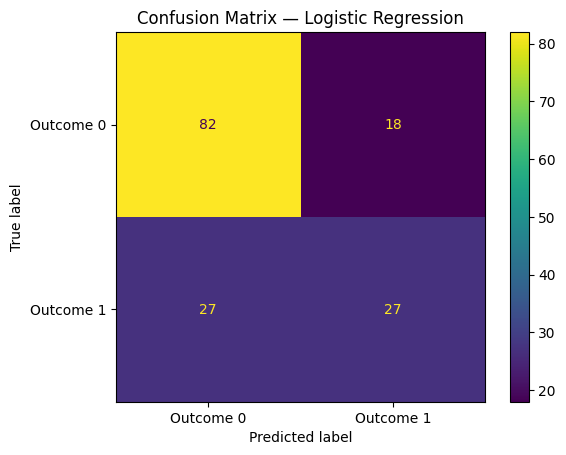

In [48]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions,
    display_labels=["Outcome 0", "Outcome 1"]
)
plt.title(f"Confusion Matrix — {best_name}")
plt.show()

In [49]:
import joblib
import os

In [50]:
os.makedirs("models", exist_ok=True)

joblib.dump(best_model, "models/diabetes_model.pkl")
joblib.dump(list(X.columns), "models/feature_names.pkl")

['models/feature_names.pkl']

In [51]:
print("Model saved successfully!")
print("Selected algorithm:", best_name)
print("Files saved in the models folder.")

Model saved successfully!
Selected algorithm: Logistic Regression
Files saved in the models folder.


In [52]:
%%writefile app.py
import streamlit as st

Overwriting app.py


In [53]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="Diabetes Risk Prediction",
    page_icon="🩺",
    layout="centered"
)

@st.cache_resource
def load_model():
    model = joblib.load("models/diabetes_model.pkl")
    features = joblib.load("models/feature_names.pkl")
    return model, features

model, features = load_model()

st.title("🩺 Diabetes Risk Prediction")
st.write(
    "An educational machine learning application "
    "that estimates a diabetes-related classification "
    "from health measurements."
)

st.warning(
    "This is an educational prototype, not a diagnostic tool. "
    "Its predictions are not clinically validated and must not "
    "be used to make medical decisions."
)

st.subheader("Enter the health measurements")

with st.form("prediction_form"):
    col1, col2 = st.columns(2)

    with col1:
        pregnancies = st.number_input(
            "Pregnancies",
            min_value=0, max_value=20, value=1
        )
        glucose = st.number_input(
            "Glucose (mg/dL)",
            min_value=0, max_value=400, value=120
        )
        blood_pressure = st.number_input(
            "Diastolic blood pressure (mmHg)",
            min_value=0, max_value=200, value=70
        )
        skin_thickness = st.number_input(
            "Skin thickness (mm)",
            min_value=0, max_value=100, value=20
        )

    with col2:
        insulin = st.number_input(
            "Insulin (dataset measurement)",
            min_value=0, max_value=1000, value=80
        )
        bmi = st.number_input(
            "BMI",
            min_value=0.0, max_value=100.0,
            value=25.0, step=0.1
        )
        dpf = st.number_input(
            "Diabetes pedigree function",
            min_value=0.0, max_value=5.0,
            value=0.5, step=0.01
        )
        age = st.number_input(
            "Age (years)",
            min_value=1, max_value=120, value=30
        )

    submitted = st.form_submit_button(
        "Predict", use_container_width=True
    )

if submitted:
    values = {
        "Pregnancies": pregnancies,
        "Glucose": glucose,
        "BloodPressure": blood_pressure,
        "SkinThickness": skin_thickness,
        "Insulin": insulin,
        "BMI": bmi,
        "DiabetesPedigreeFunction": dpf,
        "Age": age
    }

    input_df = pd.DataFrame([values])[features]

    # Avoid making a misleading prediction from
    # clearly absent or invalid key measurements.
    if glucose <= 0 or bmi <= 0 or blood_pressure <= 0:
        st.error(
            "Enter valid, positive glucose, BMI and "
            "blood pressure measurements before predicting."
        )
    else:
        prediction = int(model.predict(input_df)[0])
        score = float(model.predict_proba(input_df)[0][1])

        st.subheader("Model output")

        if prediction == 1:
            st.error(
                "The model classified this input as "
                "Outcome 1 (positive in the training dataset)."
            )
        else:
            st.success(
                "The model classified this input as "
                "Outcome 0 (negative in the training dataset)."
            )

        st.metric(
            "Model-estimated probability for Outcome 1",
            f"{score:.1%}"
        )

        st.caption(
            "This probability is not a clinically validated "
            "personal diabetes-risk estimate. A prediction "
            "cannot diagnose or rule out diabetes."
        )

Overwriting app.py
